# EAD × LGD afines: integrar el producto no equivale a multiplicar medias
## Pregunta y utilidad
La línea ya integra EAD afín y eventos de pago con LGD constante. Ahora examinamos una limitación explícita del roadmap1nov: LGD que cambia entre fechas de default. ¿Cuánto cambia la pérdida al integrar el producto de ambas trayectorias y cuándo falla la aproximación producto de medias?

H técnica preespecificada: error absoluto<1e-8 dinero frente a Simpson4096 del mismo escenario; LGD constante debe recuperar el motor previo dentro de1e-12. Datos deterministas sintéticos, no recuperaciones observadas. Adaptación matemática y auditoría local de fórmulas conocidas, no una nueva fórmula regulatoria ni descubrimiento científico.

## Original, propuesta y derivación
Para tramo $u\in[0,\Delta]$, $v=u/\Delta$, intensidades $d,p$ y fuerza $r\ge0$ en año$^{-1}$, el motor anterior calculaba $EL_i=S_iB_i L_0d\int_0^\Delta E(u)e^{-(d+p+r)u}du$.

Ahora $E(v)=E_0+(E_1-E_0)v$ en dinero y $L(v)=L_0+(L_1-L_0)v$ fracción, con EADno negativa y extremosLGDentre0y1. Son trayectorias condicionales deterministas según fecha, no variables aleatorias independientes. LGD es fracción de pérdida valorada a fecha de default; r solo descuenta default→valoración. No vuelve a descontar recuperaciones ya incorporadas en LGD.

Sea $x=(d+p+r)\Delta$, $C_i=S_iB_i[d/(d+p+r)](1-e^{-x})$. Definimos densidad normalizada $w_x(v)=e^{-xv}/A_0(x)$, $A_j(x)=\int_0^1v^j e^{-xv}dv$ y $m_j=A_j/A_0$.

Multiplicando las dos funciones afines y tomando la media ponderada:
$$EL_i=C_i[E_0L_0+(E_0\Delta L+L_0\Delta E)m_1+\Delta E\Delta Lm_2].$$
La forma equivalente sin diferencias firmadas es
$$EL_i=C_i[(1-2m_1+m_2)E_0L_0+(m_1-m_2)(E_0L_1+E_1L_0)+m_2E_1L_1].$$
Los pesos son medias de $(1-v)^2$, $v(1-v)$ y $v^2$, no negativos, y suman1 al contar dos términos cruzados. Por eso conserva positividad y $EL_i\le \max(E_0,E_1)\,P(default_i)$ si$r\ge0$, $L\le1$. Unidades: C adimensional, EADdinero, LGDfracción, ELdinero. Masa de salida no depende de LGD y se conserva.

## Momentos, existencia y estabilidad
Integración por partes da $A_1=(A_0-e^{-x})/x$, $A_2=(2A_1-e^{-x})/x$. De ahí $m_1=1/x-1/(e^x-1)$ y
$$m_2=2/x^2-(1+2/x)/(e^x-1).$$
En$x=0$, $m_1=1/2,m_2=1/3$ y necesariamente$d=0$ si todas las fuerzas son no negativas: pérdida cero. Cerca de cero, la forma de$m_2$ cancela términos grandes; usamos $A_j=\sum_{k=0}^{19}(-x)^k/[k!(k+j+1)]$ para$x<.5$, luego normalizamos. Para$x>700$ la cola exponencial es despreciable en precisiónbinary64 y usamos$2/x/x$, evitando overflow de$x^2$. El caso umbral y extremos se contrastan con Decimal90. No se reclama exactitud ilimitada para toda combinación extrema de floats.

Es la integral conocida de un polinomio contra exponencial (relacionada con gamma incompleta), no teorema nuevo. Existencia: intervalos finitos, trayectorias afines acotadas, intensidades finitas no negativas; guardas rechazan entradas fuera del contrato.

In [1]:
from src.affine_lgd import project_loss_path,second_fraction_moment
from src.affine import discounted_mean_fraction
from src.lgd_experiment import simpson
from src.term_structure import project_term_structure
import json,math
from pathlib import Path
from IPython.display import display,Image
root=Path.cwd()
anchor=project_loss_path([1.],[.24],[1.2],[100.],[20.],[.8],[.2],[.06])
oracle=simpson(100.,20.,.8,.2,.24,1.2,.06,1.)
print(anchor)
print('Independent direct Simpson4096:',oracle,'error:',abs(anchor.exact_loss-oracle))
assert abs(anchor.exact_loss-oracle)<1e-8
for x in [0.,1e-12,.499,.5,1.,10.,701.]:
 print('x,m1,m2:',x,discounted_mean_fraction(x),second_fraction_moment(x))

LossPathResult(exact_loss=5.400376882535036, product_of_means_loss=4.95448708344685, midpoint_product_loss=3.7289752312875373, constant_start_lgd_loss=6.925355349966636, default_probability=0.12717870688631303, prepayment_probability=0.6358935344315652, survival=0.23692775868212176)
Independent direct Simpson4096: 5.400376882535042 error: 6.217248937900877e-15
x,m1,m2: 0.0 0.5 0.3333333333333333
x,m1,m2: 1e-12 0.4999999999999167 0.33333333333325
x,m1,m2: 0.499 0.4585882214153947 0.29260914893200796
x,m1,m2: 0.5 0.4585059174632018 0.2925295873160092
x,m1,m2: 1.0 0.41802329313067355 0.25406987939202064
x,m1,m2: 10.0 0.09995459800899031 0.019945517610788374
x,m1,m2: 701.0 0.0014265335235378032 4.06999578755436e-06


## Identidad de covarianza temporal y contraejemplo
El producto de medias aproximaría $C_i\bar E\bar L$ con $\bar E=E_0+\Delta Em_1$, $\bar L=L_0+\Delta Lm_1$. Restando:
$$EL_i-C_i\bar E\bar L=C_i\Delta E\Delta L(m_2-m_1^2).$$
La varianza ponderada de$v$ es no negativa. Pendientes del mismo signo implican subestimación; signos contrarios, sobreestimación; trayectoria constante de cualquiera elimina el término. Es covariación de dos funciones del tiempo bajo la misma ponderación, NO dependencia estocástica de recuperaciones estimada en datos ni evidencia causal. No invalida la fórmulaIRB PD×LGD×EAD con sus parámetros correctamente definidos; la comparación es una aproximación temporal diseñada aquí.

In [2]:
x=1.5;m1=discounted_mean_fraction(x);m2=second_fraction_moment(x)
C=.24/1.5*(-math.expm1(-1.5))
for l0,l1 in [(.8,.2),(.2,.8),(.45,.45)]:
 value=project_loss_path([1.],[.24],[1.2],[100.],[20.],[l0],[l1],[.06])
 predicted=C*(-80)*(l1-l0)*(m2-m1*m1)
 observed=value.exact_loss-value.product_of_means_loss
 print('LGD endpoints:',l0,l1,'exact:',value.exact_loss,'product means:',value.product_of_means_loss,'difference:',observed)
 assert abs(observed-predicted)<1e-12

LGD endpoints: 0.8 0.2 exact: 5.400376882535036 product means: 4.95448708344685 difference: 0.44588979908818605
LGD endpoints: 0.2 0.8 exact: 3.2563173049232583 product means: 3.7022071040114435 difference: -0.44588979908818516
LGD endpoints: 0.45 0.45 exact: 3.8955123843562323 product means: 3.895512384356232 difference: 4.440892098500626e-16


## Recuperación del caso original e invariancia
LGD constante recupera el motor1nov sin reinterpretar sus parámetros. Refinar tramos conservando las MISMAS trayectorias afines y fuerzas preserva integral; convertir un pago en pendiente o modificar LGD al refinar cambia el modelo. La nueva API acepta floats de duraciones; no afirma que la LGD tenga sello de autenticidad ni que se haya extendido automáticamente el adaptador de fechas2nov.

In [3]:
old=project_term_structure([1.],[.24],[1.2],[100.],[20.],[.06],.45)
flat=project_loss_path([1.],[.24],[1.2],[100.],[20.],[.45],[.45],[.06])
assert abs(old.exact_loss-flat.exact_loss)<1e-12
assert abs(flat.exact_loss-flat.product_of_means_loss)<1e-12
edges=[0.,.03,.2,.51,1.]
dt=[b-a for a,b in zip(edges,edges[1:])]
e=[100-80*t for t in edges];l=[.8-.6*t for t in edges]
split=project_loss_path(dt,[.24]*4,[1.2]*4,e[:-1],e[1:],l[:-1],l[1:],[.06]*4)
print('Constant LGD original:',old.exact_loss,'new:',flat.exact_loss)
print('Irregular partition error:',abs(split.exact_loss-anchor.exact_loss))
assert abs(split.exact_loss-anchor.exact_loss)<1e-12

Constant LGD original: 3.8955123843562323 new: 3.8955123843562323
Irregular partition error: 8.881784197001252e-16


## Experimentos, baselines y coste
27casos completos: tres trayectoriasEAD, tresLGD y tres regímenes de intensidades/horizonte, fijados enconfig. Baseline competitivo de verdad numérica: Simpson4096 integra el producto exactamente bajo el mismoDGP y presupuesto de paneles declarado. Producto de medias y midpoint son diagnósticos de aproximación, no adversarios elegidos para fingir novedad. Convergencia8..4096paneles; escalabilidad1..360intervalos; propiedades20semillas; momento contrastado contra Decimal90.

Tiempo mediana7repeticiones25llamadas, sin instalar/importar/cargar; picoPythontracemalloc noRSS/costecloud. Simpson es generalizable a funciones no afines, ventaja que la fórmula cerrada pierde. Resultados sintéticos sin inferencia estadística ni calibración de recuperaciones.

{
  "anchor": {
    "exact_loss": 5.400376882535036,
    "product_of_means_loss": 4.95448708344685,
    "midpoint_product_loss": 3.7289752312875373,
    "constant_start_lgd_loss": 6.925355349966636,
    "default_probability": 0.12717870688631303,
    "prepayment_probability": 0.6358935344315652,
    "survival": 0.23692775868212176
  },
  "cases": 27,
  "max_absolute_error": 1.318767317570746e-11,
  "max_partition_error": 1.865174681370263e-14,
  "hypothesis": "absolute error<1e-8 money vs same-DGP Simpson4096; constant LGD recovers prior engine",
  "passed": true,
  "timings": {
    "closed_form": {
      "median_seconds": 1.0886519999075971e-05,
      "samples_seconds": [
        2.3926959997879748e-05,
        9.121079997385096e-06,
        1.0886519999075971e-05,
        9.96311999642785e-06,
        1.1079559999416234e-05,
        1.126707999901555e-05,
        8.900759999050934e-06
      ],
      "peak_python_bytes": 1112
    },
    "simpson4096": {
      "median_seconds": 0.00166

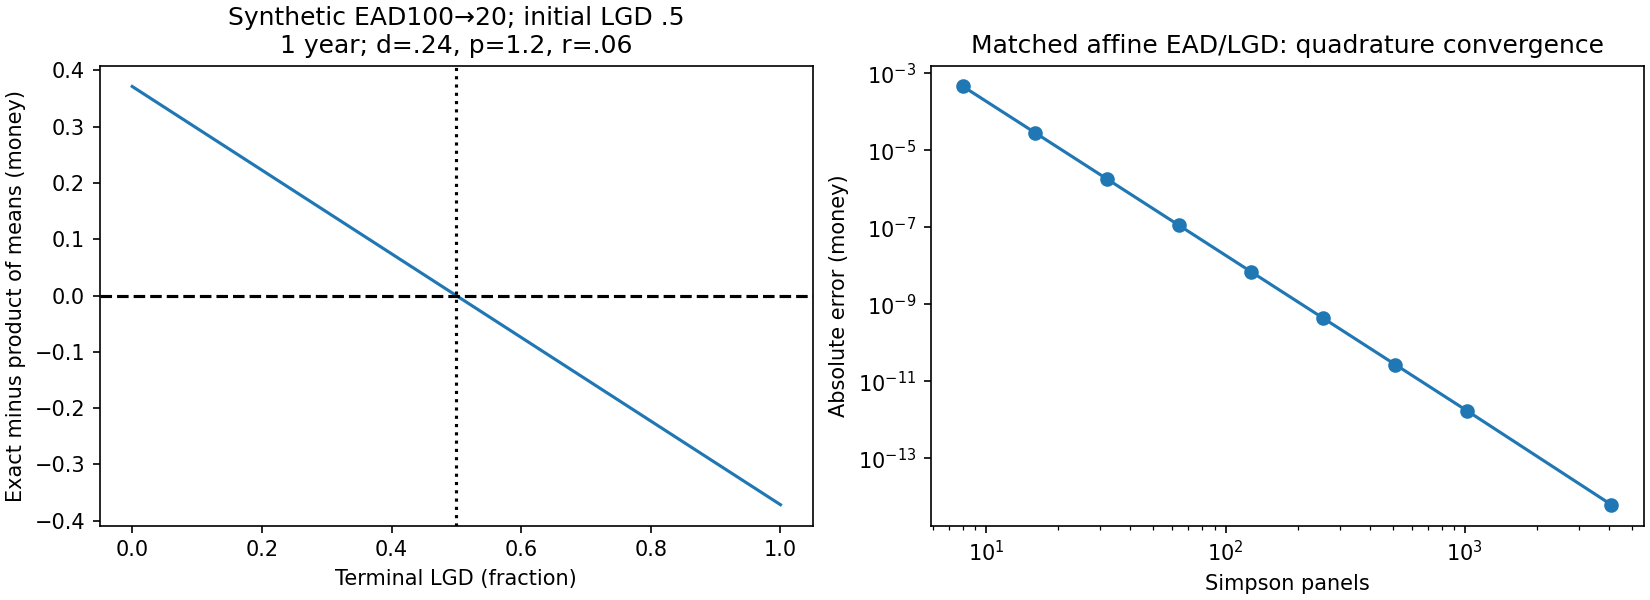

In [4]:
metrics=json.loads((root/'results/lgd_metrics.json').read_text())
print(json.dumps(metrics,indent=2))
assert metrics['passed']
display(Image(filename=str(root/'results/lgd.png')))

## Discusión, límites y siguiente prueba
Ahora el componente puede separar error de aproximación temporal EAD×LGD de cambios de exposición/recuperación. La identidad explica el signo observado; no explica por qué cambiaLGD en una cartera real. Sin fuente real autorizada, parámetrosLGDson escenarios. No hay recuperación estocástica, costos/workout detallados, descuento específico de recuperaciones ni afirmación regulatoria.

Continuar con invariancia/error y límites; ajustar si LGD no representa pérdida condicional a default; no operar sin calibración/revisión. Requiere contrato de datosLGDy fechas antes de integrarse al adaptador2nov. Referencias primarias y matriz5fuentes,14p y rúbricas eninforme1103. Cuaderno ejecutado fresh-processIPython secuencial, outputs reales; no kernelaislado ni QAfrontendJupyter.

In [5]:
zero=project_loss_path([1.],[0.],[0.],[100.],[20.],[.8],[.2],[0.])
assert zero.exact_loss==0.
print('Zero default negative:',zero)
print((root/'results/tests.txt').read_text())

Zero default negative: LossPathResult(exact_loss=0.0, product_of_means_loss=0.0, midpoint_product_loss=0.0, constant_start_lgd_loss=0.0, default_probability=0.0, prepayment_probability=0.0, survival=1.0)
test_constant_reduces_to_original (test_affine.AffineTests.test_constant_reduces_to_original) ... ok
test_decimal_oracle_small_large (test_affine.AffineTests.test_decimal_oracle_small_large) ... ok
test_invalid (test_affine.AffineTests.test_invalid) ... ok
test_negative_direction_and_zero (test_affine.AffineTests.test_negative_direction_and_zero) ... ok
test_partition_invariance_irregular (test_affine.AffineTests.test_partition_invariance_irregular) ... ok
test_properties_multiple_seeds (test_affine.AffineTests.test_properties_multiple_seeds) ... ok
test_constant_lgd_recovers_prior_engine (test_affine_lgd.LossPathTests.test_constant_lgd_recovers_prior_engine) ... ok
test_covariance_identity_and_negative_direction (test_affine_lgd.LossPathTests.test_covariance_identity_and_negative_dire